# Fraud on a Quantum Budget · Task 2
## Classical baseline + 4-qubit VQC: successive halving, superconducting noise and dynamical decoupling

One notebook, run top to bottom, from `creditcard.csv` and the common split to the final tables.

| Part | Content |
|---|---|
| **A · Classical** (Sections 0–11) | data, common split, balancing, encoding, logistic-regression baseline, cost function, AUPRC-focused metrics, 5-seed study, optional AutoGluon ceiling |
| **B · Quantum, training** (Sections 12–17) | the VQC of Dinuț et al. (2026) in PennyLane + PyTorch; **Phase 1**: ideal training, plain (Task 1 baseline) vs **successive halving** |
| **C · Quantum, testing** (Sections 18–23) | **official protocol** (depolarizing, p = 0.001 / 0.01 / 0.05); **Phase 2**: superconducting T₁/T₂ + detuning noise; **Phase 3**: dynamical decoupling; cost ledger; final tables and figures |

**Rules respected** (challenge brief, *Dataset* and *Evaluation protocol*): the split is made **before** any
balancing; every transformation is fitted on **training data only**; thresholds are chosen on **validation** scores
computed under the same noise; the **test set** keeps the real 0.17 % fraud rate and is used only for final numbers;
every result is reported as mean ± std over seeds, next to a classical reference on the same inputs.

**Environment.** Python ≥ 3.10, PennyLane 0.45, PyTorch ≥ 2.2, scikit-learn ≥ 1.4, pandas, matplotlib, seaborn,
scipy (the versions of the Task 1 notebook). AutoGluon is optional.

**Data.** Put the Kaggle file `creditcard.csv` (mlg-ulb/creditcardfraud) **in the same folder as this notebook**.

## 0 · Setup and configuration

Every number that controls the pipeline is set once, here. `SEED = 42` reproduces the **common split** used by all
participants; `SEEDS` are the five undersampling/encoder seeds of the seed study, exactly as in Part 9.3 of the
Task 1 notebook.

In [56]:
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LogNorm
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    auc,
    average_precision_score,
    confusion_matrix,
    f1_score,
    log_loss,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# ----------------------------------------------------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------------------------------------------------
SEED = 42                      # master seed: common split, first undersampling, first encoder (identical to Task 1)
SEEDS = [0, 1, 2, 3, 4]        # seed study: undersampling + encoder change, the split stays fixed (Task 1, Part 9.3)
N_COMPONENTS = 4               # one PCA component per qubit of the VQC
DATA_PATH = Path("creditcard.csv")   # the real Kaggle file, in the same folder as this notebook (relative path)
BALANCING = "undersample"      # "undersample" (identical to the VQC pipeline) or "smote" (needs imbalanced-learn)
RESULTS_CSV = Path("classical_baseline_results.csv")
RUN_AUTOGLUON = False          # optional AutoML ceiling (Section 11); needs `pip install autogluon.tabular`, ~5 min
AG_TIME_LIMIT = 300            # seconds for AutoGluon
AG_PATH = "autogluon_models"   # where AutoGluon stores its models

LEGIT_COLOR, FRAUD_COLOR = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})
warnings.filterwarnings("ignore", category=FutureWarning)

np.random.seed(SEED)

## 1 · Load the data

The real ULB dataset (Kaggle `mlg-ulb/creditcardfraud`): 284,807 transactions, 492 frauds, columns `Time`,
`V1`…`V28`, `Amount`, `Class`. It is read from **`creditcard.csv` in the same folder as this notebook**.
The cell checks the schema and the row/fraud counts, so a wrong or truncated file fails immediately.

In [57]:
EXPECTED_COLUMNS = ["Time"] + [f"V{k}" for k in range(1, 29)] + ["Amount", "Class"]

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"'{DATA_PATH}' not found in {Path.cwd()}. Download creditcard.csv from "
        "https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud and put it next to this notebook."
    )

df = pd.read_csv(DATA_PATH)
missing = set(EXPECTED_COLUMNS) - set(df.columns)
assert not missing, f"creditcard.csv lacks columns: {sorted(missing)}"
df = df[EXPECTED_COLUMNS]
df["Class"] = df["Class"].astype(int)
assert df.shape == (284_807, 31) and df["Class"].sum() == 492, (
    f"unexpected file content: shape {df.shape}, {df['Class'].sum()} frauds (expected (284807, 31) and 492)"
)
print(f"loaded {DATA_PATH}: {df.shape[0]:,} transactions, {df['Class'].sum()} frauds, "
      f"fraud rate {df['Class'].mean():.4%}")

loaded creditcard.csv: 284,807 transactions, 492 frauds, fraud rate 0.1727%


## 2 · The common split (before any balancing)

60 % / 20 % / 20 %, **stratified**, `random_state = 42`: the same two `train_test_split` calls as Task 1, Part 4.2,
so the rows are identical to the common split of every participant.

> **Why split first?** Balancing before splitting would be data leakage:
> the test set would be balanced (50 % fraud instead of 0.17 %) and every metric, AUPRC above all, would be wildly
> optimistic. Validation and test must look like the real world; only the **training** part is balanced.

In [58]:
X = df.drop(columns="Class")
y = df["Class"].to_numpy()

X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=SEED)

print(pd.DataFrame(
    {
        "rows": [len(y_train), len(y_val), len(y_test)],
        "frauds": [y_train.sum(), y_val.sum(), y_test.sum()],
        "fraud rate": [f"{part.mean():.3%}" for part in (y_train, y_val, y_test)],
    },
    index=["train", "validation", "test"],
))

# Guards: the parts are disjoint, and they are exactly the common split of the challenge
assert not set(X_train.index) & set(X_test.index) and not set(X_val.index) & set(X_test.index)
assert (len(y_test), int(y_test.sum()), int(y_val.sum())) == (56962, 98, 99), "this is not the common split"
split_file = Path("split_indices.npz")
if split_file.exists():  # saved by Part 11 of the Task 1 notebook: check row-for-row identity
    split = np.load(split_file)
    assert set(split["test"]) == set(X_test.index), "test rows differ from split_indices.npz"
    print("✅ identical to split_indices.npz")
else:  # save it, so that every later run (and the Task 1 notebook) can check against the same rows
    np.savez(split_file, train=X_train.index.to_numpy(), val=X_val.index.to_numpy(), test=X_test.index.to_numpy())
    print(f"saved {split_file}")
print("✅ common split reproduced")

              rows  frauds fraud rate
train       170883     295     0.173%
validation   56962      99     0.174%
test         56962      98     0.172%
✅ identical to split_indices.npz
✅ common split reproduced


## 3 · Balance the training set

**Random undersampling** keeps all 295 training frauds and draws as many legitimate transactions: 590 rows. This is
the function of the VQC pipeline, unchanged, so both models learn from the *same* rows for a given seed.

`BALANCING = "smote"` is offered as an option (SMOTE synthesises new frauds by interpolating between neighbouring
frauds, Chawla et al., 2002). It requires `imbalanced-learn`, is applied to the **training part only**, and makes the
classical input different from the VQC input, so keep `"undersample"` for the official comparison.

**Consequence (Bayes).** A model trained at a 1:1 class prior over-estimates fraud probabilities on real traffic:
its logit is shifted by $\log\frac{\pi}{1-\pi} \approx -6.4$ (Dal Pozzolo et al., 2015). The *ranking* (hence
AUPRC and ROC-AUC) is unaffected; probabilities and the log-loss are. Section 6 measures this explicitly.

In [59]:
def undersample(X_part, y_part, seed):
    """Identical to the VQC pipeline: all frauds + the same number of random legitimate rows, shuffled."""
    rng = np.random.default_rng(seed)
    fraud = np.flatnonzero(y_part == 1)
    legit = rng.choice(np.flatnonzero(y_part == 0), size=len(fraud), replace=False)
    keep = rng.permutation(np.concatenate([fraud, legit]))
    return X_part.iloc[keep], y_part[keep]


def balance(X_part, y_part, seed, method=BALANCING):
    if method == "undersample":
        return undersample(X_part, y_part, seed)
    if method == "smote":
        try:
            from imblearn.over_sampling import SMOTE
        except ImportError as error:
            raise ImportError("BALANCING='smote' needs: pip install imbalanced-learn") from error
        X_res, y_res = SMOTE(random_state=seed).fit_resample(X_part, y_part)
        return X_res, np.asarray(y_res)
    raise ValueError(f"unknown balancing method: {method}")


X_bal, y_bal = balance(X_train, y_train, SEED)
print(f"balanced training set ({BALANCING}): {len(y_bal)} rows, {int(y_bal.sum())} frauds")

balanced training set (undersample): 590 rows, 295 frauds


## 4 · Encode: 30 features → 4 angles in $[0, \pi]$

The same three steps as the quantum encoder (Task 1, Part 4.4), fitted on the **balanced training set only**:

1. `StandardScaler` on `Time` and `Amount` (the `V`'s are already centred);
2. `PCA(4)`: projection on the 4 leading eigenvectors of the covariance matrix;
3. `MinMaxScaler` to $[0, \pi]$, then clipping of validation/test values into $[0, \pi]$.

For a linear model the final rescaling is irrelevant (it is absorbed in the weights); it is kept so that the
logistic regression sees **exactly** the numbers that become rotation angles in the circuit.

In [60]:
class AngleEncoder:
    """Identical to the VQC pipeline (Task 1, Exercise 4.3)."""

    raw_columns = ["Time", "Amount"]

    def __init__(self, n_components, seed):
        self.scaler = StandardScaler()
        self.pca = PCA(n_components=n_components, random_state=seed)
        self.angles = MinMaxScaler(feature_range=(0, np.pi))

    def _scaled(self, frame):
        out = frame.copy()
        out[self.raw_columns] = self.scaler.transform(frame[self.raw_columns])
        return out.to_numpy()

    def fit(self, frame):
        self.scaler.fit(frame[self.raw_columns])
        self.angles.fit(self.pca.fit_transform(self._scaled(frame)))
        return self

    def transform(self, frame):
        return np.clip(self.angles.transform(self.pca.transform(self._scaled(frame))), 0, np.pi)


encoder = AngleEncoder(N_COMPONENTS, SEED).fit(X_bal)
Z_bal, Z_val, Z_test = encoder.transform(X_bal), encoder.transform(X_val), encoder.transform(X_test)
FEATURES = [f"PC{k + 1}" for k in range(N_COMPONENTS)]
print("explained variance per component:", encoder.pca.explained_variance_ratio_.round(3))
print(f"total: {encoder.pca.explained_variance_ratio_.sum():.1%}   angle ranges: [{Z_bal.min():.2f}, {Z_bal.max():.2f}]")

explained variance per component: [0.664 0.117 0.073 0.035]
total: 88.9%   angle ranges: [0.00, 3.14]


## 5 · The linear baseline: logistic regression

### 5.1 Model
$$p(x) = \sigma(w\cdot x + b), \qquad \sigma(z) = \frac{1}{1+e^{-z}},\qquad x\in[0,\pi]^4,$$
five parameters ($w_1,\dots,w_4,b$) against the VQC's 32. The sigmoid is a Fermi–Dirac occupation with the linear
score $w\cdot x+b$ as (minus) the energy.

### 5.2 Cost function: binary cross-entropy (log-loss)
For $N$ examples with labels $y_k\in\{0,1\}$ and predicted probabilities $p_k$:
$$\boxed{\;J(w,b) = -\frac{1}{N}\sum_{k=1}^{N}\Big[\,y_k\log p_k + (1-y_k)\log(1-p_k)\Big]\;}$$
This is the negative log-likelihood of a Bernoulli model, i.e. the KL divergence between the labels and the model up
to a constant, and it is **exactly** the loss minimised by the VQC (`torch.nn.BCELoss`, with
$p = (1-\langle Z_0\rangle)/2$). The two costs are therefore directly comparable.

scikit-learn actually minimises $J(w,b) + \frac{1}{2CN}\lVert w\rVert^2$ (L2 penalty, $C=1$, the same default as the
VQC comparison of Task 1). The penalty is a training device, so below we always report the **pure** BCE $J$.

The objective is **convex** (its Hessian $\frac1N\sum_k p_k(1-p_k)\,\tilde x_k\tilde x_k^{\top}$ is positive
semi-definite), so L-BFGS reaches the global optimum from any start: no seed dependence from the optimiser, unlike
the VQC's non-convex, periodic landscape.

In [61]:
logreg = LogisticRegression(max_iter=1000).fit(Z_bal, y_bal)   # same settings as the reference of Task 1, Part 9.2

coefficients = pd.DataFrame(
    {"weight w_i": logreg.coef_[0], "|w_i| rank": np.argsort(np.argsort(-np.abs(logreg.coef_[0]))) + 1},
    index=FEATURES,
)
print(coefficients.round(4))
print(f"intercept b: {logreg.intercept_[0]:.4f}")
print("A positive weight means: larger angle on that qubit → higher fraud probability.")

     weight w_i  |w_i| rank
PC1     -5.7523           1
PC2      2.2095           3
PC3     -4.0837           2
PC4      1.3984           4
intercept b: 15.3620
A positive weight means: larger angle on that qubit → higher fraud probability.


## 6 · Training, validation and test cost

We compute $J$ with our own NumPy implementation and check it against `sklearn.metrics.log_loss`.

- **Training cost**: on the balanced 590 rows. This is the number to compare with the VQC's training BCE
  (about 0.37 after 30 epochs in Task 1, Part 7).
- **Validation / test cost**: on the realistic 0.17 % data. These are *much* larger than the training cost even for
  a good ranker, because the probabilities are calibrated for a 50 % prior (Section 3). This is not over-fitting.
- **Prior-corrected test cost**: shift every logit by $\log\frac{\pi}{1-\pi} - \log\frac{0.5}{0.5}$ with $\pi$ the
  *training-set* fraud rate (no leakage). This Bayes correction repairs calibration and leaves AUPRC unchanged,
  since a constant logit shift is monotone.

In [62]:
def bce(y_true, p, eps=1e-15):
    """Binary cross-entropy J, written out (clipping avoids log(0))."""
    p = np.clip(p, eps, 1 - eps)
    return float(-np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p)))


def prior_correct(p, prior_train_balanced=0.5, prior_real=None):
    """Bayes correction of probabilities learned at prior 0.5 to the real prior: constant logit shift."""
    logit = np.log(p / (1 - p))
    shift = np.log(prior_real / (1 - prior_real)) - np.log(prior_train_balanced / (1 - prior_train_balanced))
    return 1 / (1 + np.exp(-(logit + shift)))


PRIOR_REAL = y_train.mean()   # estimated on TRAINING data only
p_train = logreg.predict_proba(Z_bal)[:, 1]
p_val = logreg.predict_proba(Z_val)[:, 1]
p_test = logreg.predict_proba(Z_test)[:, 1]
p_test_corrected = prior_correct(np.clip(p_test, 1e-12, 1 - 1e-12), prior_real=PRIOR_REAL)

costs = pd.Series(
    {
        "training cost (balanced, 590 rows)": bce(y_bal, p_train),
        "validation cost (0.17% fraud)": bce(y_val, p_val),
        "test cost (0.17% fraud)": bce(y_test, p_test),
        "test cost, Bayes prior-corrected": bce(y_test, p_test_corrected),
    },
    name="BCE / log-loss",
)
print(costs.round(4))

# our formula must agree with scikit-learn's implementation
assert np.isclose(costs.iloc[0], log_loss(y_bal, p_train)) and np.isclose(costs.iloc[2], log_loss(y_test, p_test))
assert np.isclose(average_precision_score(y_test, p_test), average_precision_score(y_test, p_test_corrected))
print("✅ BCE matches sklearn.log_loss; prior correction leaves AUPRC unchanged")

training cost (balanced, 590 rows)    0.2425
validation cost (0.17% fraud)         0.1916
test cost (0.17% fraud)               0.1920
test cost, Bayes prior-corrected      0.0060
Name: BCE / log-loss, dtype: float64
✅ BCE matches sklearn.log_loss; prior correction leaves AUPRC unchanged


## 7 · Why not ordinary linear regression?

Least squares fits $\hat y = w\cdot x + b$ to 0/1 labels. Three problems:

1. its outputs are **not probabilities**: they leave $[0,1]$, so the BCE (which needs $\log p$ and $\log(1-p)$) is
   undefined for them;
2. squared error punishes a *confidently correct* prediction ($\hat y = 3$ for a fraud) as much as a wrong one;
3. the decision rule $\hat y \ge 0.5$ is set by the least-squares geometry, not by a likelihood.

Yet, as a *ranker*, its scores can still give a reasonable AUPRC: ranking metrics only see the order. The plot shows
both models against the logistic score $z = w\cdot x + b$.

linear regression: 0.2% of test predictions fall outside [0, 1] (range -0.27 to 1.59)
AUPRC as a ranker: linear regression 0.705   logistic regression 0.704


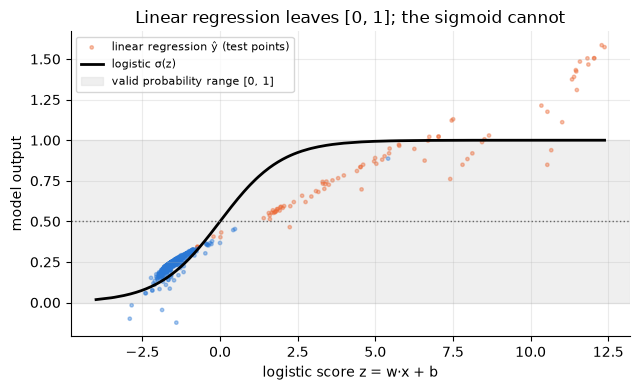

In [63]:
linreg = LinearRegression().fit(Z_bal, y_bal)
yhat_lin_test = linreg.predict(Z_test)
z_test = logreg.decision_function(Z_test)

outside = np.mean((yhat_lin_test < 0) | (yhat_lin_test > 1))
print(f"linear regression: {outside:.1%} of test predictions fall outside [0, 1] "
      f"(range {yhat_lin_test.min():.2f} to {yhat_lin_test.max():.2f})")
print(f"AUPRC as a ranker: linear regression {average_precision_score(y_test, yhat_lin_test):.3f}   "
      f"logistic regression {average_precision_score(y_test, p_test):.3f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
order = np.argsort(z_test)
rng_plot = np.random.default_rng(0)
show = np.concatenate([np.flatnonzero(y_test == 1), rng_plot.choice(np.flatnonzero(y_test == 0), 3000, replace=False)])
ax.scatter(z_test[show], yhat_lin_test[show], s=6, alpha=0.4,
           c=np.where(y_test[show] == 1, FRAUD_COLOR, LEGIT_COLOR), label="linear regression ŷ (test points)")
ax.plot(z_test[order], 1 / (1 + np.exp(-z_test[order])), color="black", linewidth=2, label="logistic σ(z)")
ax.axhspan(0, 1, color="0.85", alpha=0.4, zorder=0, label="valid probability range [0, 1]")
ax.axhline(0.5, color="0.4", linestyle=":", linewidth=1)
ax.set_xlabel("logistic score z = w·x + b")
ax.set_ylabel("model output")
ax.set_title("Linear regression leaves [0, 1]; the sigmoid cannot")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 8 · Metrics for a 0.17 % problem

### Why AUPRC is the gold standard here
- **Accuracy** of the "always legitimate" model is 99.83 %: useless.
- **ROC-AUC** $= P(s_{\text{fraud}} > s_{\text{legit}})$ uses the false-positive *rate* $FP/(FP+TN)$. With ~57,000
  legitimate test transactions, an FPR of 1 % is still ~570 false alarms against 98 frauds, yet the ROC point looks
  excellent.
- **Precision** $TP/(TP+FP)$ counts false alarms in absolute terms. The precision–recall curve, and its area
  **AUPRC**, therefore measure what an analyst team experiences. A random ranker has AUPRC ≈ fraud rate (0.0017),
  not 0.5, so the scale is honest about how hard the problem is.

### Two ways to compute the area
- `average_precision_score` (**AP**, the challenge's AUPRC): the step sum $\sum_n (R_n - R_{n-1})P_n$, no
  interpolation.
- `auc(recall, precision)`: trapezoidal integration of the same curve. Linear interpolation between PR points is
  **optimistic** (precision does not vary linearly between operating points; Davis & Goadrich, 2006). It is reported
  for completeness only; **use AP in every comparison with the VQC**.

### The decision threshold
Chosen to **maximise F1 on the validation set**, never on test (identical to `choose_threshold` of Task 1).

In [64]:
def choose_threshold(y_true, scores):
    """F1-optimal threshold on (y_true, scores). Identical to the VQC protocol."""
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return thresholds[np.argmax(f1[:-1])]


def evaluate(y_true, scores, threshold):
    """Same keys as Task 1's evaluate(), plus log-loss and the trapezoidal PR area."""
    predicted = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    precision_curve, recall_curve, _ = precision_recall_curve(y_true, scores)
    in_unit_interval = np.all((scores >= 0) & (scores <= 1))
    return {
        "AUPRC": average_precision_score(y_true, scores),
        "AUPRC_trapz": auc(recall_curve, precision_curve),
        "AUROC": roc_auc_score(y_true, scores),
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "F1": f1_score(y_true, predicted, zero_division=0),
        "MCC": matthews_corrcoef(y_true, predicted),
        "log_loss": bce(y_true, scores) if in_unit_interval else np.nan,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }


threshold = choose_threshold(y_val, p_val)
results_lr = evaluate(y_test, p_test, threshold)

print(f"threshold chosen on validation: {threshold:.4f}")
print(f"\nconfusion matrix on test (rows: actual, columns: predicted)\n"
      f"                 legit   fraud\n"
      f"  actual legit  {results_lr['TN']:6d}  {results_lr['FP']:6d}\n"
      f"  actual fraud  {results_lr['FN']:6d}  {results_lr['TP']:6d}")
print()
print(pd.Series({k: v for k, v in results_lr.items() if k not in ("TP", "FP", "FN", "TN")}).round(4).to_string())
print(f"\nno-skill AUPRC (test fraud rate): {y_test.mean():.4f}")

threshold chosen on validation: 0.7552

confusion matrix on test (rows: actual, columns: predicted)
                 legit   fraud
  actual legit   56838      26
  actual fraud      18      80

AUPRC          0.7039
AUPRC_trapz    0.7025
AUROC          0.9775
precision      0.7547
recall         0.8163
F1             0.7843
MCC            0.7845
log_loss       0.1920

no-skill AUPRC (test fraud rate): 0.0017


## 9 · Three-panel figure

1. **Confusion matrix** at the validation threshold, on a logarithmic colour scale (counts span 56,800 to tens),
   with the test log-loss in the title.
2. **ROC curve** with ROC-AUC.
3. **Precision–recall curve** with AUPRC (AP) in the legend and the **no-skill** line at the test fraud rate.

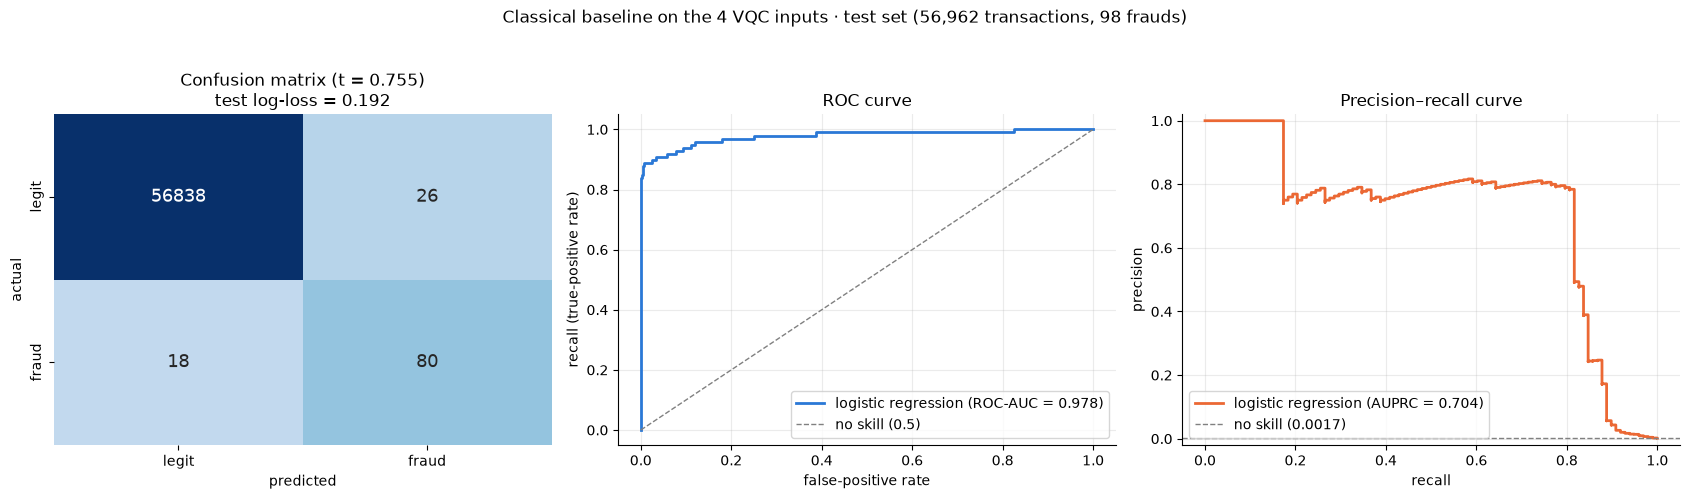

In [65]:
cm = confusion_matrix(y_test, (p_test >= threshold).astype(int), labels=[0, 1])
fpr, tpr, _ = roc_curve(y_test, p_test)
prec_curve, rec_curve, _ = precision_recall_curve(y_test, p_test)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", norm=LogNorm(vmin=1, vmax=cm.max()), cbar=False,
            xticklabels=["legit", "fraud"], yticklabels=["legit", "fraud"], ax=axes[0], annot_kws={"size": 13})
axes[0].set_xlabel("predicted")
axes[0].set_ylabel("actual")
axes[0].set_title(f"Confusion matrix (t = {threshold:.3f})\ntest log-loss = {results_lr['log_loss']:.3f}")
axes[0].grid(False)

axes[1].plot(fpr, tpr, color=LEGIT_COLOR, linewidth=2, label=f"logistic regression (ROC-AUC = {results_lr['AUROC']:.3f})")
axes[1].plot([0, 1], [0, 1], color="0.5", linestyle="--", linewidth=1, label="no skill (0.5)")
axes[1].set(xlabel="false-positive rate", ylabel="recall (true-positive rate)", title="ROC curve")
axes[1].legend(loc="lower right")

axes[2].step(rec_curve, prec_curve, where="post", color=FRAUD_COLOR, linewidth=2,
             label=f"logistic regression (AUPRC = {results_lr['AUPRC']:.3f})")
axes[2].axhline(y_test.mean(), color="0.5", linestyle="--", linewidth=1, label=f"no skill ({y_test.mean():.4f})")
axes[2].set(xlabel="recall", ylabel="precision", title="Precision–recall curve", ylim=(-0.02, 1.02))
axes[2].legend(loc="lower left")

fig.suptitle(f"Classical baseline on the 4 VQC inputs · test set ({len(y_test):,} transactions, {y_test.sum()} frauds)",
             y=1.03, fontsize=12)
plt.tight_layout()
plt.show()

## 10 · Seed study (mean ± std over 5 seeds)

The challenge requires results over at least 5 seeds. As in Task 1, Part 9.3, the **split stays fixed** while the
undersampling draw and the encoder (fitted on that draw) change with the seed. Logistic regression is convex, so its
spread comes **only** from the data draw; any extra spread of the VQC comes from its non-convex training.

The table is saved to `classical_baseline_results.csv`, with the same metric names as `evaluate_under_noise`, so it
can be concatenated with the VQC results.

`prepare_seed(seed)` is the **single source of truth** for the data of one seed; the quantum part (Part B) calls the
same function, so the VQC and the logistic regression of a given seed see identical rows and identical angles.

In [66]:
def prepare_seed(seed):
    """Balanced training draw + encoder fitted on it, for one seed. Shared by the classical and quantum parts."""
    X_s, y_s = balance(X_train, y_train, seed)
    enc = AngleEncoder(N_COMPONENTS, seed).fit(X_s)
    return {
        "seed": seed,
        "Z_train": enc.transform(X_s), "y_train": np.asarray(y_s),
        "Z_val": enc.transform(X_val), "Z_test": enc.transform(X_test),
    }


SEED_DATA = {seed: prepare_seed(seed) for seed in SEEDS}   # reused by the VQC

rows = []
for seed in SEEDS:
    d = SEED_DATA[seed]
    model = LogisticRegression(max_iter=1000).fit(d["Z_train"], d["y_train"])
    s_train = model.predict_proba(d["Z_train"])[:, 1]
    s_val, s_test = model.predict_proba(d["Z_val"])[:, 1], model.predict_proba(d["Z_test"])[:, 1]
    rows.append({
        "model": "logistic regression", "seed": seed, "p": 0.0,
        "train_BCE": bce(d["y_train"], s_train),
        **evaluate(y_test, s_test, choose_threshold(y_val, s_val)),
    })

seed_results = pd.DataFrame(rows)
seed_results.to_csv(RESULTS_CSV, index=False)
summary_cols = ["AUPRC", "AUROC", "precision", "recall", "F1", "MCC", "train_BCE", "log_loss"]
summary = seed_results[summary_cols].agg(["mean", "std"]).T
summary["mean ± std"] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(summary["mean"], summary["std"])]
print(summary[["mean ± std"]].to_string())
print(f"\nsaved per-seed results to {RESULTS_CSV.resolve()}")

              mean ± std
AUPRC      0.703 ± 0.010
AUROC      0.976 ± 0.003
precision  0.776 ± 0.029
recall     0.808 ± 0.013
F1         0.791 ± 0.019
MCC        0.791 ± 0.018
train_BCE  0.246 ± 0.009
log_loss   0.194 ± 0.002

saved per-seed results to /home/celine/projects/breaq-2026/classical_baseline_results.csv


## 11 · Optional: AutoML ceiling with AutoGluon (off by default)

**What AutoGluon is.** An open-source AutoML library (Amazon, `autogluon.tabular`). One call to
`TabularPredictor.fit` trains a whole portfolio of classical models (gradient-boosted trees: LightGBM, CatBoost,
XGBoost; random forests; extra trees; k-nearest neighbours; small neural nets), tunes them, and stacks them into a
weighted ensemble, all optimising the metric you ask for, here `average_precision` (= AUPRC).

**Why it is here.** The challenge only *requires* a logistic regression. AutoGluon answers a different question:
*what is the best any classical model can do with these four PCA angles?* If even the best ensemble barely beats the
logistic regression, the four features are the bottleneck, not the model, and the VQC cannot be expected to do much
better either. It is a ceiling, useful for the "what limits us" slide, not part of the judged protocol.

**Why off by default.** It is a heavy install and takes ~5 minutes. Set `RUN_AUTOGLUON = True` in Section 0 to run it.

Protocol details, kept fair:
- **train** = the same balanced 590 rows; **tuning data** = the validation set (realistic 0.17 %), used by AutoGluon
  for early stopping, model selection and ensemble weights. That is legitimate: validation is for decisions;
- **test** is used only for the final table;
- for every model we report AUPRC, ROC-AUC, log-loss, and precision/recall **at a threshold chosen on validation**
  (AutoGluon's own `precision`/`recall` in the raw leaderboard use 0.5, which is meaningless for a balanced-trained
  model on 0.17 % data);
- the logistic-regression row is added with the same metric code.

Note: AutoGluon is not bit-for-bit reproducible across machines and versions; treat its numbers as a strong
reference, not as an exact benchmark.

In [67]:
AUTOGLUON_AVAILABLE = False
if RUN_AUTOGLUON:
    try:
        from autogluon.tabular import TabularPredictor
        AUTOGLUON_AVAILABLE = True
    except ImportError:
        print("AutoGluon is not installed (pip install autogluon.tabular): skipping this benchmark.")
else:
    print("RUN_AUTOGLUON = False: skipping the optional AutoML ceiling.")

if AUTOGLUON_AVAILABLE:
    train_df = pd.DataFrame(Z_bal, columns=FEATURES).assign(Class=y_bal)
    val_df = pd.DataFrame(Z_val, columns=FEATURES).assign(Class=y_val)
    test_df = pd.DataFrame(Z_test, columns=FEATURES).assign(Class=y_test)

    predictor = TabularPredictor(
        label="Class", problem_type="binary", eval_metric="average_precision", path=AG_PATH, verbosity=1
    ).fit(train_data=train_df, tuning_data=val_df, presets="medium_quality", time_limit=AG_TIME_LIMIT)

    # AutoGluon's own leaderboard (its precision/recall use a 0.5 threshold)
    raw_leaderboard = predictor.leaderboard(
        test_df, extra_metrics=["log_loss", "roc_auc", "precision", "recall"], silent=True
    )
    print(raw_leaderboard[["model", "score_test", "log_loss", "roc_auc", "precision", "recall"]].to_string(index=False))

    # Our leaderboard: every model scored with the protocol's metric code and a validation-chosen threshold
    positive = predictor.positive_class
    model_names = predictor.model_names() if hasattr(predictor, "model_names") else predictor.get_model_names()
    rows_ag = []
    for name in model_names:
        s_val = predictor.predict_proba(val_df.drop(columns="Class"), model=name)[positive].to_numpy()
        s_test = predictor.predict_proba(test_df.drop(columns="Class"), model=name)[positive].to_numpy()
        rows_ag.append({"model": name, **evaluate(y_test, s_test, choose_threshold(y_val, s_val))})
    rows_ag.append({"model": "LogisticRegression (ours)", **results_lr})

    leaderboard = (pd.DataFrame(rows_ag)[["model", "AUPRC", "log_loss", "AUROC", "precision", "recall", "F1", "MCC"]]
                   .sort_values("AUPRC", ascending=False).reset_index(drop=True))
    print("\nprotocol leaderboard (test set, threshold chosen on validation):")
    print(leaderboard.round(4).to_string(index=False))

RUN_AUTOGLUON = False: skipping the optional AutoML ceiling.


---
# Part B · The quantum classifier: architecture and Phase 1 (ideal training)

## 12 · Quantum setup and configuration

The VQC follows Dinuț, Constantinescu & Alexandrescu (2026, *Electronics* 15(11), 2489) as rebuilt in the Task 1
notebook: 4 qubits, a **ZZ feature map** (2 repetitions, full entanglement), an **EfficientSU2-style ansatz**
(3 repetitions of $R_Y R_Z$ + linear CNOT ladder 0→1→2→3, plus a final rotation layer, weights of shape (4, 4, 2)),
readout $p = (1-\langle Z_0\rangle)/2$, trained with Adam on the binary cross-entropy.

**Run profile.** Everything quantum loops over `QUANTUM_SEEDS`. `RUN_PROFILE = "full"` uses the 5 seeds the
challenge requires; `"quick"` uses 2 seeds to check the whole notebook end to end in a fraction of the time.
Trained weights are cached in `vqc_trained_weights.pt`, so the testing sections can be re-run without retraining.

In [68]:
import json
import time

import pennylane as qml
import torch

print("pennylane", qml.__version__, "| torch", torch.__version__)

RUN_PROFILE = "full"                         # "full" (5 seeds, judged) or "quick" (2 seeds, end-to-end check)
QUANTUM_SEEDS = SEEDS if RUN_PROFILE == "full" else SEEDS[:2]

# ---- architecture (Task 1 / Dinuț et al. 2026) ------------------------------------------------------------------
N_QUBITS = 4
FEATURE_MAP_REPS = 2
ANSATZ_REPS = 3                              # weights: (ANSATZ_REPS + 1, N_QUBITS, 2) = (4, 4, 2)
BATCH_SIZE = 32
LEARNING_RATE = 0.05

# ---- Phase 1a: plain training, identical to the Task 1 baseline ---------------------------------------------------
EPOCHS_PLAIN = 30                            # full validation set scored after every epoch, best epoch kept

# ---- Phase 1b: successive halving (SH) ----------------------------------------------------------------------------
SH_N_INIT = 8                                # random initialisations entering the tournament
SH_FRACTIONS = [0.25, 0.5, 1.0]              # fraction of the 590 balanced training rows per rung (doubling)
SH_SHOTS = [100, 1024, 1024]                 # shots per circuit execution per rung (scoring; and training in the ledger)
SH_EPOCHS_PER_RUNG = 2                       # training epochs per candidate per rung
SH_FINAL_EPOCHS = 18                         # extra epochs for the winner on the full balanced set
# SH_VAL_FRACTION = 0.2                        # stratified validation subset used for every SH decision
SH_VAL_EVERY = 3                             # winner: validate every 5 epochs (budgeted validation)
SH_SHOT_TRAINING = False                     # True: train with real shot noise via parameter-shift (~20-50x slower)
SH_VAL_LEGIT = 5000                          # SH validation subset: all validation frauds + this many legit rows

# ---- cost ledger --------------------------------------------------------------------------------------------------
SHOTS_PER_EXECUTION = 1024                   # shots of the plain baseline (Task 1, Part 8)

# ---- official noise protocol (challenge) ---------------------------------------------------------------------------
NOISE_LEVELS = [0.001, 0.01, 0.05]           # depolarizing probability per gate
NATIVE_GATES = {"RX", "RY", "RZ", "Rot", "Hadamard", "CNOT", "CZ"}
RUN_OFFICIAL_DD = True                       # also evaluate the DD circuit under the official depolarizing model

# ---- Phase 2/3: superconducting hardware model (illustrative transmon numbers) ------------------------------------
HW_T1 = 100e-6                               # energy relaxation time T1 [s]
HW_T2 = 80e-6                                # coherence time T2 [s] (must satisfy T2 <= 2 T1)
HW_T_1Q = 40e-9                              # single-qubit gate duration [s]
HW_T_2Q = 400e-9                             # CNOT duration [s]
HW_DETUNING_HZ = (20e3, -15e3, 25e3, -10e3)  # quasi-static frequency offset of each qubit [Hz]
SC_STRESS = [1, 3, 10]                       # every error source multiplied by this factor (1 = the profile above)
SC_ABLATION_STRESS = 3                       # Markovian-only ablation (detuning switched off) at this stress
SC_SEEDS = QUANTUM_SEEDS[:2]                 # superconducting study is extra (not judged): 2 seeds by default
SC_VAL_FRACTION = 0.2                        # stratified validation subset for the noisy threshold

WEIGHTS_FILE = Path("vqc_trained_weights.pt")
CONFIG_FILE = Path("vqc_trained_config.json")
REUSE_SAVED_WEIGHTS = True                   # skip training if weights for the same configuration exist


def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)


def init_weights(seed):
    """Uniform angles in [0, 2π), as in Task 1."""
    generator = torch.Generator().manual_seed(seed)
    return torch.nn.Parameter(
        2 * np.pi * torch.rand(ANSATZ_REPS + 1, N_QUBITS, 2, generator=generator, dtype=torch.float64)
    )


set_seed(SEED)
print(f"profile: {RUN_PROFILE}   quantum seeds: {QUANTUM_SEEDS}   superconducting-study seeds: {SC_SEEDS}")

pennylane 0.45.1 | torch 2.14.1+cpu
profile: full   quantum seeds: [0, 1, 2, 3, 4]   superconducting-study seeds: [0, 1]


## 13 · The superconducting noise model (Phase 2) and dynamical decoupling (Phase 3)

### Decoherence channels
A transmon qubit idling or being driven for a time $t$ undergoes two Markovian processes:

- **$T_1$ relaxation** (energy decay $|1\rangle\to|0\rangle$): **amplitude damping** with
  $K_0=\begin{pmatrix}1&0\\0&\sqrt{1-\gamma_1}\end{pmatrix}$, $K_1=\begin{pmatrix}0&\sqrt{\gamma_1}\\0&0\end{pmatrix}$,
  $\gamma_1(t) = 1-e^{-t/T_1}$;
- **pure dephasing** (loss of phase memory): **phase damping** with
  $K_0=\begin{pmatrix}1&0\\0&\sqrt{1-\gamma_\phi}\end{pmatrix}$, $K_1=\begin{pmatrix}0&0\\0&\sqrt{\gamma_\phi}\end{pmatrix}$.
  With the pure-dephasing rate $\Gamma_\phi = 1/T_2 - 1/(2T_1)$, the coherence must decay as $e^{-\Gamma_\phi t}$,
  so $\sqrt{1-\gamma_\phi} = e^{-\Gamma_\phi t}$, i.e. $\gamma_\phi(t) = 1-e^{-2\Gamma_\phi t}$.

Together they give exactly the textbook decay: populations relax with $T_1$, coherences with
$e^{-t/(2T_1)}\,e^{-\Gamma_\phi t} = e^{-t/T_2}$.

### Quasi-static detuning (the part an echo can fix)
Real qubits also carry slow frequency offsets $\Delta_q$ (calibration drift, flux noise, ZZ crosstalk). On an idle
qubit this is a **coherent** phase $R_Z(2\pi\Delta_q t)$, constant over the circuit. It is the reversible part of the
$T_2^*$ decay.

### Where the noise goes (explicitly, gate by gate)
- after every single-qubit gate (duration $t_{1q}$): $T_1$ + $T_2$ channels on its qubit;
- after every CNOT (duration $t_{2q}$): $T_1$ + $T_2$ channels on its two qubits; **the two spectator qubits are idle
  for $t_{2q}$**: $T_1$ + $T_2$ channels + detuning phase.

`stress` multiplies every rate and the detuning, to scan from today's hardware (stress 1) to much worse devices.

### Dynamical decoupling: a Hahn echo inside every CNOT window
On each spectator qubit, the idle window is split around two $\pi$ pulses:
$$\underbrace{R_Z(\varphi)}_{\text{idle }t/2}\;\;X\;\;\underbrace{R_Z(\varphi)}_{\text{idle }t/2}\;\;X
  \;=\; X R_Z(\varphi) X\, R_Z(\varphi) = R_Z(-\varphi)R_Z(\varphi) = \mathbb 1 .$$
The coherent detuning phase is **refocused exactly**. Two remarks matter for an honest reading:

1. Two $X$ gates applied **back to back**, with no idle time between them, are the identity and refocus nothing.
   The echo must *bracket* the idle interval, as here.
2. Markovian phase damping is invariant under $X$ conjugation, so an echo **cannot** undo it. An echo partly
   symmetrises amplitude damping, which helps a little. Pulses also cost gates, and under a gate-based noise model
   (the official depolarizing protocol) idle qubits get no noise at all, so DD can only add noise there.

The $X$ pulses are implemented as `qml.RX(π)`: the physical microwave $\pi$ pulse of a transmon, equal to
`qml.X` up to a global phase, and a native gate of the official noise model (so it is charged correctly).

In [69]:
class SuperconductingNoise:
    """T1 amplitude damping + T2 phase damping after every gate, idle decoherence + coherent detuning on spectators."""

    def __init__(self, stress=1.0, detuning=True, T1=HW_T1, T2=HW_T2, t_1q=HW_T_1Q, t_2q=HW_T_2Q,
                 detuning_hz=HW_DETUNING_HZ):
        assert T2 <= 2 * T1, "physical constraint: T2 <= 2 T1"
        self.stress, self.detuning = float(stress), bool(detuning)
        self.T1, self.T2, self.t_1q, self.t_2q = T1, T2, t_1q, t_2q
        self.rate_phi = 1 / T2 - 1 / (2 * T1)                 # pure-dephasing rate Γ_φ
        self.omega = 2 * np.pi * np.asarray(detuning_hz)      # angular detuning per qubit [rad/s]

    def gamma_amplitude(self, t):
        return 1 - np.exp(-self.stress * t / self.T1)

    def gamma_phase(self, t):
        return 1 - np.exp(-2 * self.stress * self.rate_phi * t)

    def decohere(self, wire, t):
        """Markovian T1 + T2 channels for a duration t on one wire (inside a QNode)."""
        g1, gp = self.gamma_amplitude(t), self.gamma_phase(t)
        if g1 > 0:
            qml.AmplitudeDamping(float(g1), wires=wire)
        if gp > 0:
            qml.PhaseDamping(float(gp), wires=wire)

    def idle(self, wire, t):
        """An idle qubit: Markovian decoherence + quasi-static coherent detuning phase."""
        self.decohere(wire, t)
        if self.detuning and t > 0:
            qml.RZ(float(self.stress * self.omega[wire] * t), wires=wire)

    def describe(self):
        return pd.Series({
            "γ1 per 1q gate": self.gamma_amplitude(self.t_1q), "γφ per 1q gate": self.gamma_phase(self.t_1q),
            "γ1 per CNOT": self.gamma_amplitude(self.t_2q), "γφ per CNOT": self.gamma_phase(self.t_2q),
            "max detuning phase per CNOT window [rad]": float(np.abs(self.stress * self.omega * self.t_2q).max()),
        })


print("stress = 1 profile:")
print(SuperconductingNoise(stress=1).describe().map(lambda v: f"{v:.2e}").to_string())

stress = 1 profile:
γ1 per 1q gate                              4.00e-04
γφ per 1q gate                              6.00e-04
γ1 per CNOT                                 3.99e-03
γφ per CNOT                                 5.98e-03
max detuning phase per CNOT window [rad]    6.28e-02


## 14 · The circuit, built once, with optional noise and DD

`make_vqc_circuit(noise=None, dd=False)` returns a quantum function `circuit(x, weights) → ⟨Z₀⟩`:

- `noise=None, dd=False`: the **ideal Task 1 circuit**, gate for gate (93 gates, 33 CNOTs);
- `noise=SuperconductingNoise(...)`: the same gates with the channels of Section 13 inserted explicitly;
- `dd=True`: an RX(π)–RX(π) echo on both spectators of every CNOT.

Training (Phase 1) always uses the **ideal** circuit on `default.qubit` (state vector, exact backprop). Testing
(Phases 2–3 and the official protocol) uses `default.mixed` (density matrices). The two loops never share a device.

In [70]:
def make_vqc_circuit(noise=None, dd=False, n_qubits=N_QUBITS, fm_reps=FEATURE_MAP_REPS, ansatz_reps=ANSATZ_REPS):
    wires = list(range(n_qubits))
    t_1q = noise.t_1q if noise is not None else 0.0
    t_2q = noise.t_2q if noise is not None else 0.0

    def gate_1q(gate, angle, wire):
        gate(angle, wires=wire)
        if noise is not None:
            noise.decohere(wire, t_1q)

    def hadamard(wire):
        qml.Hadamard(wires=wire)
        if noise is not None:
            noise.decohere(wire, t_1q)

    def cnot(control, target):
        qml.CNOT(wires=[control, target])
        if noise is not None:
            noise.decohere(control, t_2q)
            noise.decohere(target, t_2q)
        for q in wires:                                    # the spectators are idle during the CNOT
            if q in (control, target):
                continue
            if dd:                                         # Hahn echo bracketing the idle window
                half = 0.5 * max(t_2q - 2 * t_1q, 0.0)
                if noise is not None:
                    noise.idle(q, half)
                gate_1q(qml.RX, np.pi, q)
                if noise is not None:
                    noise.idle(q, half)
                gate_1q(qml.RX, np.pi, q)
            elif noise is not None:
                noise.idle(q, t_2q)

    def feature_map(x):                                    # ZZ feature map, full entanglement (Task 1, Part 6.1)
        for _ in range(fm_reps):
            for i in wires:
                hadamard(i)
                gate_1q(qml.RZ, 2 * x[..., i], i)
            for i in wires:
                for j in range(i + 1, n_qubits):
                    cnot(i, j)
                    gate_1q(qml.RZ, 2 * (np.pi - x[..., i]) * (np.pi - x[..., j]), j)
                    cnot(i, j)

    def ansatz(weights):                                   # EfficientSU2-style, linear ladder (Task 1, Part 6.2)
        for layer in range(ansatz_reps + 1):
            for i in wires:
                gate_1q(qml.RY, weights[layer, i, 0], i)
                gate_1q(qml.RZ, weights[layer, i, 1], i)
            if layer < ansatz_reps:
                for i in range(n_qubits - 1):
                    cnot(i, i + 1)

    def circuit(x, weights):
        feature_map(x)
        ansatz(weights)
        return qml.expval(qml.PauliZ(0))

    return circuit


ideal_circuit = make_vqc_circuit()                  # Task 1 baseline circuit
dd_circuit = make_vqc_circuit(dd=True)              # same + echo pulses (noiseless: identical output)

ideal_device = qml.device("default.qubit", wires=N_QUBITS)
ideal_qnode = qml.QNode(ideal_circuit, ideal_device, interface="torch", diff_method="backprop")


def fraud_probability(x, weights):
    """p = (1 - <Z_0>)/2 on the ideal simulator (exact, differentiable by backprop)."""
    return torch.clamp((1 - ideal_qnode(x, weights)) / 2, 0.0, 1.0)


def make_sampled_model(shots, device_seed):
    """Same circuit estimated from a finite number of shots (what hardware returns). Parameter-shift gradients."""
    device = qml.device("default.qubit", wires=N_QUBITS, seed=device_seed)
    qnode = qml.set_shots(qml.QNode(ideal_circuit, device, interface="torch", diff_method="parameter-shift"),
                          shots=shots)
    return lambda x, weights: torch.clamp((1 - qnode(x, weights)) / 2, 0.0, 1.0)


def predict(Z, weights, model=None, chunk=20000):
    """Scores of many transactions, no gradients (Task 1, Part 7)."""
    model = model or fraud_probability
    X_t = torch.tensor(Z)
    with torch.no_grad():
        return torch.cat([model(X_t[k:k + chunk], weights) for k in range(0, len(X_t), chunk)]).numpy()


def sc_predict(Z, weights, noise, dd, chunk=2000):
    """Testing loop, Phases 2-3: density-matrix simulation under the superconducting model, with or without DD."""
    qnode = qml.QNode(make_vqc_circuit(noise=noise, dd=dd), qml.device("default.mixed", wires=N_QUBITS),
                      interface="torch")
    X_t = torch.tensor(Z)
    with torch.no_grad():
        scores = [torch.clamp((1 - qnode(X_t[k:k + chunk], weights)) / 2, 0.0, 1.0) for k in range(0, len(X_t), chunk)]
    return torch.cat(scores).numpy()


# ---- official challenge protocol: copied verbatim from Task 1, Parts 10.3 and 11.2 --------------------------------
def noisy_qnode(circuit_fn, p, n_wires=N_QUBITS):
    noisy_device = qml.noise.insert(qml.device("default.mixed", wires=n_wires), qml.DepolarizingChannel, p,
                                    position="all")
    qnode = qml.QNode(circuit_fn, noisy_device, interface="torch", diff_method="backprop")
    return qml.transforms.decompose(qnode, gate_set=NATIVE_GATES)


def noisy_predict(Z, weights, p, circuit_fn=ideal_circuit, readout=lambda expval: (1 - expval) / 2,
                  n_wires=N_QUBITS, chunk=2000):
    noisy_circuit = noisy_qnode(circuit_fn, p, n_wires)
    X_t = torch.tensor(Z)
    with torch.no_grad():
        return torch.cat([readout(noisy_circuit(X_t[k:k + chunk], weights)) for k in range(0, len(X_t), chunk)]).numpy()


def noise_locations(circuit_fn, *args, n_wires=N_QUBITS):
    qnode = qml.transforms.decompose(qml.QNode(circuit_fn, qml.device("default.qubit", wires=n_wires)),
                                     gate_set=NATIVE_GATES)
    return sum(size * count for size, count in qml.specs(qnode)(*args)["resources"].gate_sizes.items())


def gate_counts(circuit_fn, *args, n_wires=N_QUBITS):
    qnode = qml.transforms.decompose(qml.QNode(circuit_fn, qml.device("default.qubit", wires=n_wires)),
                                     gate_set=NATIVE_GATES)
    return dict(qml.specs(qnode)(*args)["resources"].gate_types)


def evaluate_under_noise(circuit_fn, weights, Z_valid, Z_test_part, y_valid=y_val, y_test_part=y_test,
                         readout=lambda expval: (1 - expval) / 2, noise_levels=NOISE_LEVELS, n_wires=N_QUBITS):
    clean = qml.QNode(circuit_fn, qml.device("default.qubit", wires=n_wires), interface="torch")
    with torch.no_grad():
        clean_val = readout(clean(torch.tensor(Z_valid), weights)).numpy()
        clean_test = readout(clean(torch.tensor(Z_test_part), weights)).numpy()
    rows = []
    for p in [0.0, *noise_levels]:
        if p == 0.0:
            val_scores, test_scores = clean_val, clean_test
        else:
            val_scores = noisy_predict(Z_valid, weights, p, circuit_fn, readout, n_wires)
            test_scores = noisy_predict(Z_test_part, weights, p, circuit_fn, readout, n_wires)
        threshold = choose_threshold(y_valid, val_scores)
        rows.append({"p": p, **evaluate(y_test_part, test_scores, threshold),
                     "Spearman rho": spearmanr(clean_test, test_scores).statistic, "threshold": threshold})
    return pd.DataFrame(rows).set_index("p")


def executions_per_example(circuit_fn, weights, Z_sample, shots=SHOTS_PER_EXECUTION):
    """Hardware executions for one example's gradient, counted by qml.Tracker under parameter-shift (Task 1, Part 8)."""
    device = qml.device("default.qubit", wires=N_QUBITS, seed=SEED)
    qnode = qml.set_shots(qml.QNode(circuit_fn, device, interface="torch", diff_method="parameter-shift"),
                          shots=shots)
    w = torch.nn.Parameter(weights.detach().clone())
    n_examples = 2                                         # one example at a time: no broadcasting ambiguity
    with qml.Tracker(device) as tracker:
        for k in range(n_examples):
            loss = (1 - qnode(torch.tensor(Z_sample[k]), w)) / 2
            loss.backward()
    return tracker.totals["executions"] / n_examples

## 15 · Self-checks (seconds; run before any long computation)

The challenge brief warns that generated code often calls PennyLane functions that have moved. These checks fail
loudly and early:

1. gate counts of the ideal circuit = Task 1 (8 H, 36 RZ, 16 RY, 33 CNOT = 93 gates, **126** noise locations);
2. the DD circuit adds exactly 2 RX per spectator per CNOT (33 × 2 × 2 = 132 RX);
3. noiseless, DD changes nothing (RX(π)² = −𝟙, a global phase);
4. the official noisy simulator at p = 0 reproduces the ideal scores (to 1e-6: default.mixed and default.qubit agree to ~1e-7, far below the ≥ 1e-3 effect of any real noise);
5. the superconducting model at stress 0 reproduces the ideal scores (with and without DD);
6. finite-shot estimates scatter around the exact scores with the expected $1/\sqrt{N}$ size;
7. executions per gradient counted by `qml.Tracker` (Task 1 found 41, not 1 + 2·32 = 65: 12 parameters lie outside
   the light cone of qubit 0).

In [71]:
def check_close(name, got, ref, tol):
    got = got.numpy() if torch.is_tensor(got) else np.asarray(got)
    err = float(np.abs(got - ref).max())
    print(f"  [{'ok' if err < tol else 'FAIL'}] {name}: max |Δp| = {err:.1e} (tol {tol:.0e})")
    assert err < tol, f"{name}: max |Δp| = {err:.2e} exceeds {tol:.0e}"


TOL_STATEVECTOR = 1e-10   # default.qubit vs default.qubit: double-precision agreement
TOL_MIXED = 1e-6          # default.qubit vs default.mixed: measured ~4e-8 to 1e-7 (16×16 density matrices);
                          # any real circuit/noise error moves p by >= 1e-3, shot noise by ~1.6e-2

check_data = SEED_DATA[QUANTUM_SEEDS[0]]
x_check = torch.tensor(check_data["Z_val"][:6])
w_check = init_weights(SEED)

# 1-2 · gate counts and noise locations
counts_ideal = gate_counts(ideal_circuit, x_check[0], w_check)
counts_dd = gate_counts(dd_circuit, x_check[0], w_check)
print("ideal circuit gates:", counts_ideal)
print("DD circuit gates:   ", counts_dd)
assert counts_ideal == {"Hadamard": 8, "RZ": 36, "CNOT": 33, "RY": 16}, "ideal circuit differs from Task 1"
assert counts_dd.get("RX", 0) == 132 and {k: v for k, v in counts_dd.items() if k != "RX"} == counts_ideal

LOCATIONS = {"ideal": noise_locations(ideal_circuit, x_check[0], w_check),
             "DD": noise_locations(dd_circuit, x_check[0], w_check)}
print("noise locations (official model):", LOCATIONS)
assert LOCATIONS["ideal"] == 126 and LOCATIONS["DD"] == 126 + 132

# 3-5 · every simulator path reproduces the ideal scores when noise is off
print("\nnoise-off consistency:")
with torch.no_grad():
    exact = ((1 - ideal_qnode(x_check, w_check)) / 2).numpy()
    dd_exact = ((1 - qml.QNode(dd_circuit, ideal_device, interface="torch")(x_check, w_check)) / 2).numpy()
check_close("DD pulses, noiseless (state vector)", dd_exact, exact, TOL_STATEVECTOR)
check_close("official depolarizing model at p = 0", noisy_predict(check_data["Z_val"][:6], w_check, 0.0),
            exact, TOL_MIXED)
for dd_flag in (False, True):
    zero_noise = sc_predict(check_data["Z_val"][:6], w_check, SuperconductingNoise(stress=0.0), dd=dd_flag)
    check_close(f"superconducting model at stress 0, DD={dd_flag}", zero_noise, exact, TOL_MIXED)

# 6 · finite shots scatter around the exact value with the binomial size sqrt(p(1-p)/N)
N_SHOTS_CHECK = 1024
sampled = predict(check_data["Z_val"][:6], w_check, model=make_sampled_model(N_SHOTS_CHECK, SEED))
sigma = np.sqrt(exact * (1 - exact) / N_SHOTS_CHECK)
z_scores = np.abs(sampled - exact) / sigma
print(f"\n{N_SHOTS_CHECK}-shot estimates vs exact: max |Δp| = {np.abs(sampled - exact).max():.3f}, "
      f"max deviation = {z_scores.max():.1f} σ (σ ≈ {sigma.mean():.3f})")
assert z_scores.max() < 5, "shot estimates are too far from the exact value: check make_sampled_model / set_shots"

# 7 · hardware executions per training example
E_TRACKED = executions_per_example(ideal_circuit, w_check, check_data["Z_val"])
E_FORMULA = 1 + 2 * w_check.numel()
print(f"executions per training example: tracked {E_TRACKED:.0f}, formula 1 + 2P = {E_FORMULA}")
if E_TRACKED != 41:
    print(f"  note: Task 1 tracked 41; got {E_TRACKED:.0f} (PennyLane version may count differently, check Section 18)")
print("\n✅ all self-checks passed")


ideal circuit gates: {'Hadamard': 8, 'RZ': 36, 'CNOT': 33, 'RY': 16}
DD circuit gates:    {'Hadamard': 8, 'RZ': 36, 'CNOT': 33, 'RX': 132, 'RY': 16}
noise locations (official model): {'ideal': 126, 'DD': 258}

noise-off consistency:
  [ok] DD pulses, noiseless (state vector): max |Δp| = 3.3e-16 (tol 1e-10)
  [ok] official depolarizing model at p = 0: max |Δp| = 3.7e-08 (tol 1e-06)
  [ok] superconducting model at stress 0, DD=False: max |Δp| = 3.7e-08 (tol 1e-06)
  [ok] superconducting model at stress 0, DD=True: max |Δp| = 3.7e-08 (tol 1e-06)

1024-shot estimates vs exact: max |Δp| = 0.015, max deviation = 1.4 σ (σ ≈ 0.011)
executions per training example: tracked 41, formula 1 + 2P = 65

✅ all self-checks passed


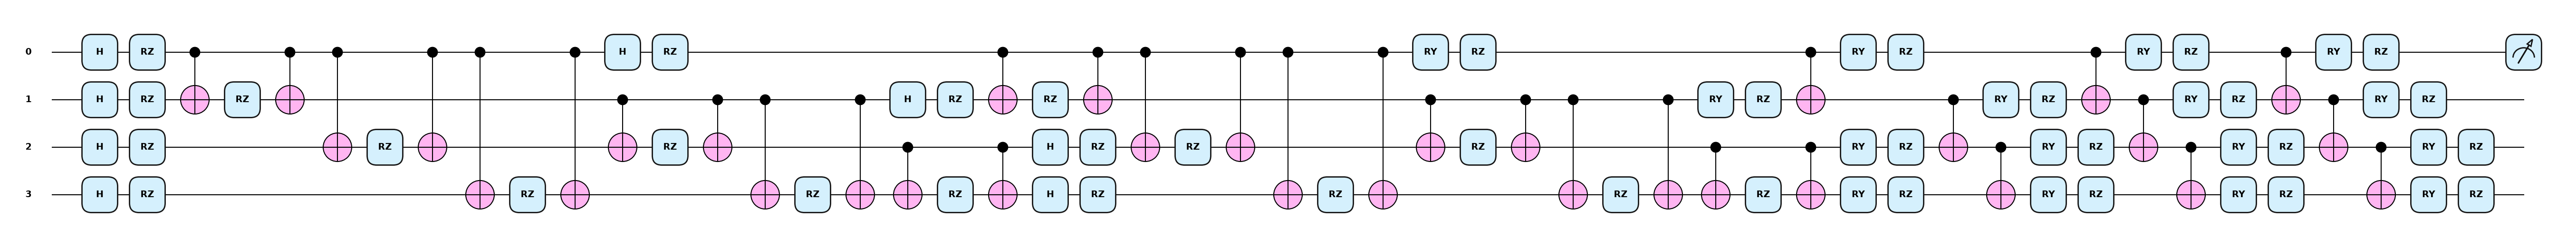

In [79]:
fig, ax = qml.draw_mpl(ideal_qnode, style="pennylane")(x_check[0], w_check)
fig.savefig("circuit.png", dpi=200, bbox_inches="tight")


## 16 · Phase 1a: plain ideal training (the Task 1 baseline)

The training loop of Task 1, Part 7, unchanged: 30 epochs on the 590 balanced rows, mini-batches of 32, Adam,
binary cross-entropy; after every epoch the **full** validation set is scored and the epoch with the best validation
AUPRC is kept. This model is **deliverable 1** of the challenge (the baseline).

Physics recap: the loss is $L(\theta) = -\frac1N\sum_k[y_k\log p_k + (1-y_k)\log(1-p_k)]$ with
$p_k = (1-\langle\psi(x_k,\theta)|Z_0|\psi(x_k,\theta)\rangle)/2$, and `loss.backward()` differentiates through the
simulated state vector.

In [72]:
def train_plain(Z_train_part, y_train_part, Z_valid, y_valid, seed, epochs=EPOCHS_PLAIN):
    """Task 1's train_vqc, unchanged in logic."""
    set_seed(seed)
    weights = init_weights(seed)
    optimizer = torch.optim.Adam([weights], lr=LEARNING_RATE)
    loss_fn = torch.nn.BCELoss()
    X_t = torch.tensor(Z_train_part)
    y_t = torch.tensor(y_train_part, dtype=torch.float64)
    history, best_ap, best_weights = [], -1.0, None
    for epoch in range(1, epochs + 1):
        order = torch.randperm(len(X_t))
        losses = []
        for k in range(0, len(X_t), BATCH_SIZE):
            idx = order[k:k + BATCH_SIZE]
            optimizer.zero_grad()
            loss = loss_fn(fraud_probability(X_t[idx], weights), y_t[idx])
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        val_ap = average_precision_score(y_valid, predict(Z_valid, weights))
        history.append({"epoch": epoch, "train loss": np.mean(losses), "validation AUPRC": val_ap})
        if val_ap > best_ap:
            best_ap, best_weights = val_ap, weights.detach().clone()
    ledger = [
        {"phase": "training", "example_gradients": epochs * len(X_t), "shots_per_execution": SHOTS_PER_EXECUTION},
        {"phase": "validation", "scored_examples": epochs * len(Z_valid), "shots_per_execution": SHOTS_PER_EXECUTION},
    ]
    return best_weights, pd.DataFrame(history), ledger

## 17 · Phase 1b: successive halving (SH), an operations-research budget allocator

**Idea** (Jamieson & Talwalkar 2016; the core of Hyperband, Li et al. 2018). Most random initialisations of a VQC end
in mediocre local minima of its non-convex, periodic landscape. Instead of training one of them fully, start
**8 candidates** cheaply, keep the best half, give the survivors **twice the data and more shots**, and repeat until
one remains; only the winner is trained to the end.

| Rung | Training data (of the 590 balanced rows) | Shots | Candidates in → out |
|---|---|---|---|
| 1 | 25 % (stratified) | 100 | 8 → 4 |
| 2 | 50 % (nested: contains rung 1) | 1024 | 4 → 2 |
| 3 | 100 % | 1024 | 2 → 1 |
| final | 100 %, 10 more epochs, validated every 5 epochs | 1024 | 1 |

**Design choices, and why.**
- Rung score = validation AUPRC estimated from the rung's shots, on all 99 validation frauds + 5,000 legitimate rows, legit rows weighted by ≈ 11.4 so the score estimates AUPRC at the real 0.17 % rate. ROC-AUC was tried first and rejected: all models score 0.95–0.97 on it, so it cannot separate good from bad fraud rankers (it is dominated by the easy bulk of legit transactions, while AUPRC depends on the top of the ranking).
- *Shots.* Rung scoring uses **real sampled shots** (100, then 1024): low-shot noise is what makes early rungs cheap
  and slightly unreliable, exactly the trade-off SH manages. Training uses exact simulator gradients by default
  (`SH_SHOT_TRAINING = False`), because simulating parameter-shift with shots is 20–50× slower on a laptop; the
  **cost ledger still charges** every training step as parameter-shift executions × the rung's shots, i.e. what
  the hardware would pay. Set `SH_SHOT_TRAINING = True` to train with genuine shot noise.
- *Budgeted validation.* The plain baseline scores all 56,962 validation transactions after each of its 30 epochs:
  1.7 M executions, 60 % of its whole budget. SH scores ~11,400 transactions only at decision points.
- *Honest accounting.* The ledger includes **every** candidate, including the discarded ones.

In [73]:
def stratified_orders(y_part, rng):
    """One random permutation per class: prefixes of these give nested stratified subsets."""
    return [rng.permutation(np.flatnonzero(y_part == c)) for c in (0, 1)]


def nested_subset(orders, fraction):
    return np.sort(np.concatenate([order[: max(1, int(round(fraction * len(order))))] for order in orders]))


def sh_validation_subset(y_part, n_legit, seed):
    """All frauds + n_legit random legit rows. Legit rows get weight N_legit/n_legit, so weighted AUPRC estimates the
    AUPRC of the full validation set at its real 0.17 % fraud rate."""
    rng = np.random.default_rng(seed)
    fraud, legit_all = np.flatnonzero(y_part == 1), np.flatnonzero(y_part == 0)
    legit = rng.choice(legit_all, size=min(n_legit, len(legit_all)), replace=False)
    idx = np.sort(np.concatenate([fraud, legit]))
    weight = np.where(y_part[idx] == 1, 1.0, len(legit_all) / len(legit))
    return idx, weight


def run_epochs(weights, optimizer, Z, y_part, epochs, model, generator):
    loss_fn = torch.nn.BCELoss()
    X_t, y_t = torch.tensor(Z), torch.tensor(y_part, dtype=torch.float64)
    losses = []
    for _ in range(epochs):
        order = torch.randperm(len(X_t), generator=generator)
        for k in range(0, len(X_t), BATCH_SIZE):
            idx = order[k:k + BATCH_SIZE]
            optimizer.zero_grad()
            loss = loss_fn(model(X_t[idx], weights), y_t[idx])
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
    return float(np.mean(losses))


def sampled_val_ap(weights, Z, y_part, sample_weight, shots, device_seed):
    """Validation AUPRC from finite-shot scores (what the hardware would give), prevalence-corrected by weights."""
    scores = predict(Z, weights, model=make_sampled_model(shots, device_seed), chunk=2000)
    return average_precision_score(y_part, scores, sample_weight=sample_weight)


def successive_halving(d, run_seed):
    rng = np.random.default_rng(run_seed)
    train_orders = stratified_orders(d["y_train"], rng)
    val_idx, val_w = sh_validation_subset(y_val, SH_VAL_LEGIT, run_seed + 10_000)
    Z_vs, y_vs = d["Z_val"][val_idx], y_val[val_idx]

    candidates = []
    for k in range(SH_N_INIT):
        init_seed = 1000 * run_seed + k
        w = init_weights(init_seed)
        candidates.append({"id": k, "init_seed": init_seed, "weights": w,
                           "optimizer": torch.optim.Adam([w], lr=LEARNING_RATE),
                           "generator": torch.Generator().manual_seed(init_seed)})

    ledger, log, rung = [], [], 0
    while True:
        r = min(rung, len(SH_FRACTIONS) - 1)
        fraction, shots = SH_FRACTIONS[r], SH_SHOTS[r]
        idx = nested_subset(train_orders, fraction)
        Z_r, y_r = d["Z_train"][idx], d["y_train"][idx]
        model = make_sampled_model(shots, 7 * run_seed + rung) if SH_SHOT_TRAINING else fraud_probability
        for cand in candidates:
            loss = run_epochs(cand["weights"], cand["optimizer"], Z_r, y_r, SH_EPOCHS_PER_RUNG, model,
                              cand["generator"])
            cand["score"] = sampled_val_ap(cand["weights"], Z_vs, y_vs, val_w, shots,
                                           device_seed=100_000 * run_seed + 100 * rung + cand["id"])
            ledger.append({"phase": "training", "example_gradients": SH_EPOCHS_PER_RUNG * len(idx),
                           "shots_per_execution": shots})
            ledger.append({"phase": "validation", "scored_examples": len(Z_vs), "shots_per_execution": shots})
            log.append({"seed": run_seed, "rung": rung + 1, "train rows": len(idx), "shots": shots,
                        "candidate": cand["id"], "train loss": loss, "val AUPRC (sampled)": cand["score"]})
        candidates.sort(key=lambda c: c["score"], reverse=True)
        keep = max(1, len(candidates) // 2)
        survivors = {c["id"] for c in candidates[:keep]}
        for row in log[-len(candidates):]:
            row["survives"] = row["candidate"] in survivors
        candidates = candidates[:keep]
        if len(candidates) == 1:
            break
        rung += 1

    # ---- finish the winner on the full balanced set; choose ONLY among final-stage checkpoints ----------------------
    # (the rung score is the max of noisy draws, biased upward: comparing against it would keep the under-trained
    #  rung-3 weights. All checkpoints below share data, shots and validation subset, so they are comparable.)
    winner = candidates[0]
    final_shots = SH_SHOTS[-1]
    model = make_sampled_model(final_shots, 7 * run_seed + 99) if SH_SHOT_TRAINING else fraud_probability
    checkpoints, done = [], 0
    while done < SH_FINAL_EPOCHS:
        n_epochs = min(SH_VAL_EVERY, SH_FINAL_EPOCHS - done)
        run_epochs(winner["weights"], winner["optimizer"], d["Z_train"], d["y_train"], n_epochs, model,
                   winner["generator"])
        done += n_epochs
        score = sampled_val_ap(winner["weights"], Z_vs, y_vs, val_w, final_shots,
                               device_seed=100_000 * run_seed + 9_000 + done)
        checkpoints.append({"epoch": done, "score": score, "weights": winner["weights"].detach().clone()})
        ledger.append({"phase": "training", "example_gradients": n_epochs * len(d["Z_train"]),
                       "shots_per_execution": final_shots})
        ledger.append({"phase": "validation", "scored_examples": len(Z_vs), "shots_per_execution": final_shots})
    best = max(checkpoints, key=lambda c: c["score"])
    info = {"winner": winner["id"], "winner init seed": winner["init_seed"],
            "best final epoch": best["epoch"], "best val AUPRC (sampled)": best["score"]}
    return best["weights"], pd.DataFrame(log), ledger, info


### Run Phase 1 for every seed (or reload cached weights)

For each seed: the balanced draw and the encoder come from `prepare_seed(seed)` (Section 10), so the VQC sees
exactly the inputs of the logistic regression of the same seed. Both trainings run on the ideal simulator.

In [74]:
TRAIN_CONFIG = {
    "seeds": QUANTUM_SEEDS, "epochs_plain": EPOCHS_PLAIN, "lr": LEARNING_RATE, "batch": BATCH_SIZE,
    "sh": [SH_N_INIT, SH_FRACTIONS, SH_SHOTS, SH_EPOCHS_PER_RUNG, SH_FINAL_EPOCHS, SH_VAL_LEGIT, SH_VAL_EVERY,
           SH_SHOT_TRAINING],
    "arch": [N_QUBITS, FEATURE_MAP_REPS, ANSATZ_REPS], "balancing": BALANCING,
    "sh_selection": "weighted AUPRC, final-stage checkpoints only",   # bump this string whenever SH logic changes
}

cached = (REUSE_SAVED_WEIGHTS and WEIGHTS_FILE.exists() and CONFIG_FILE.exists()
          and json.loads(CONFIG_FILE.read_text()) == json.loads(json.dumps(TRAIN_CONFIG)))
if cached:
    WEIGHTS = {int(k): v for k, v in torch.load(WEIGHTS_FILE).items()}
    LEDGER_ROWS = pd.read_csv("vqc_cost_ledger_raw.csv").to_dict("records")
    SH_LOG = pd.read_csv("vqc_successive_halving_log.csv")
    PLAIN_HISTORY = pd.read_csv("vqc_plain_history.csv")
    SH_INFO = pd.read_csv("vqc_successive_halving_info.csv")
    print(f"reloaded trained weights for seeds {sorted(WEIGHTS)} from {WEIGHTS_FILE}")
else:
    WEIGHTS, LEDGER_ROWS, sh_logs, plain_histories, sh_infos = {}, [], [], [], []
    for seed in QUANTUM_SEEDS:
        d = SEED_DATA[seed]
        start = time.time()
        w_plain, history, ledger_plain = train_plain(d["Z_train"], d["y_train"], d["Z_val"], y_val, seed)
        t_plain = time.time() - start
        start = time.time()
        w_sh, sh_log, ledger_sh, info = successive_halving(d, seed)
        t_sh = time.time() - start
        WEIGHTS[seed] = {"plain": w_plain, "sh": w_sh}
        LEDGER_ROWS += [{"method": "VQC plain", "seed": seed, **row} for row in ledger_plain]
        LEDGER_ROWS += [{"method": "VQC + SH", "seed": seed, **row} for row in ledger_sh]
        sh_logs.append(sh_log)
        plain_histories.append(history.assign(seed=seed))
        sh_infos.append({"seed": seed, **info})
        print(f"seed {seed}: plain {t_plain:5.0f} s (best val AUPRC {history['validation AUPRC'].max():.3f}) | "
              f"SH {t_sh:5.0f} s (winner #{info['winner']}, val AUPRC {info['best val AUPRC (sampled)']:.3f} "
              f"@ final epoch {info['best final epoch']})")
    SH_LOG = pd.concat(sh_logs, ignore_index=True)
    PLAIN_HISTORY = pd.concat(plain_histories, ignore_index=True)
    SH_INFO = pd.DataFrame(sh_infos)
    torch.save({str(k): v for k, v in WEIGHTS.items()}, WEIGHTS_FILE)
    CONFIG_FILE.write_text(json.dumps(TRAIN_CONFIG))
    pd.DataFrame(LEDGER_ROWS).to_csv("vqc_cost_ledger_raw.csv", index=False)
    SH_LOG.to_csv("vqc_successive_halving_log.csv", index=False)
    PLAIN_HISTORY.to_csv("vqc_plain_history.csv", index=False)
    SH_INFO.to_csv("vqc_successive_halving_info.csv", index=False)

print(SH_INFO.round(4).to_string(index=False))
print("\nsuccessive-halving tournament of the first seed:")
print(SH_LOG[SH_LOG["seed"] == QUANTUM_SEEDS[0]].round(4).to_string(index=False))

# guard: training budgets must match, so any AUPRC gap comes from selection, not from extra training
grads = pd.DataFrame(LEDGER_ROWS).query("phase == 'training'").groupby(["method", "seed"])["example_gradients"].sum()
print("\ntraining example-gradients per seed:", grads.groupby("method").mean().to_dict())


seed 0: plain    42 s (best val AUPRC 0.527) | SH    28 s (winner #6, val AUPRC 0.521 @ final epoch 3)
seed 1: plain    46 s (best val AUPRC 0.593) | SH    29 s (winner #6, val AUPRC 0.695 @ final epoch 9)
seed 2: plain    44 s (best val AUPRC 0.575) | SH    28 s (winner #6, val AUPRC 0.611 @ final epoch 12)
seed 3: plain    42 s (best val AUPRC 0.584) | SH    28 s (winner #5, val AUPRC 0.717 @ final epoch 6)
seed 4: plain    43 s (best val AUPRC 0.562) | SH    28 s (winner #4, val AUPRC 0.495 @ final epoch 12)
 seed  winner  winner init seed  best final epoch  best val AUPRC (sampled)
    0       6                 6                 3                    0.5213
    1       6              1006                 9                    0.6951
    2       6              2006                12                    0.6114
    3       5              3005                 6                    0.7171
    4       4              4004                12                    0.4952

successive-halving tournam

In [75]:
rows = []
for _, info in SH_INFO.iterrows():
    seed, d = int(info["seed"]), SEED_DATA[int(info["seed"])]
    models = {
        "plain · at init": init_weights(seed),
        "plain · trained": WEIGHTS[seed]["plain"],
        "SH · winner at init": init_weights(int(info["winner init seed"])),
        "SH · trained": WEIGHTS[seed]["sh"],
    }
    for name, w in models.items():
        rows.append({"seed": seed, "model": name,
                     "train BCE": bce(d["y_train"], predict(d["Z_train"], w)),
                     "val AUPRC": average_precision_score(y_val, predict(d["Z_val"], w)),
                     "test AUPRC": average_precision_score(y_test, predict(d["Z_test"], w))})

learn = pd.DataFrame(rows)
order = ["plain · at init", "plain · trained", "SH · winner at init", "SH · trained"]
print(learn.groupby("model")[["train BCE", "val AUPRC", "test AUPRC"]]
      .agg(lambda s: f"{s.mean():.3f} ± {s.std():.3f}").loc[order].to_string())

# where does the AUPRC come from? (test AUPRC, mean over seeds)
m = learn.groupby("model")["test AUPRC"].mean()
print(f"\nSH: selection gain (winner init − random init) = {m['SH · winner at init'] - m['plain · at init']:+.3f}, "
      f"learning gain (trained − winner init) = {m['SH · trained'] - m['SH · winner at init']:+.3f}")
print(f"plain: learning gain = {m['plain · trained'] - m['plain · at init']:+.3f}")

# when does validation AUPRC peak? an early peak = the model stops improving the ranking early
best_epoch = PLAIN_HISTORY.loc[PLAIN_HISTORY.groupby("seed")["validation AUPRC"].idxmax(), ["seed", "epoch"]]
print("\nplain best epoch per seed:", dict(zip(best_epoch["seed"], best_epoch["epoch"])),
      "| SH best final epoch:", dict(zip(SH_INFO["seed"], SH_INFO["best final epoch"])))


                         train BCE      val AUPRC     test AUPRC
model                                                           
plain · at init      0.760 ± 0.242  0.099 ± 0.162  0.118 ± 0.202
plain · trained      0.386 ± 0.018  0.568 ± 0.026  0.580 ± 0.053
SH · winner at init  0.688 ± 0.116  0.162 ± 0.125  0.159 ± 0.128
SH · trained         0.375 ± 0.013  0.548 ± 0.036  0.537 ± 0.042

SH: selection gain (winner init − random init) = +0.041, learning gain (trained − winner init) = +0.377
plain: learning gain = +0.462

plain best epoch per seed: {0: 5, 1: 13, 2: 14, 3: 5, 4: 11} | SH best final epoch: {0: 3, 1: 9, 2: 12, 3: 6, 4: 12}


In [76]:
from scipy.stats import wilcoxon

per_seed = learn.pivot(index="seed", columns="model", values="test AUPRC")
diff = per_seed["SH · trained"] - per_seed["plain · trained"]
print("test AUPRC, SH − plain per seed:", diff.round(3).to_dict())
print(f"mean difference {diff.mean():+.3f} ± {diff.std() / np.sqrt(len(diff)):.3f} (s.e.), "
      f"Wilcoxon p = {wilcoxon(diff).pvalue:.2f}  (n = {len(diff)}: p cannot go below 0.06)")


test AUPRC, SH − plain per seed: {0: 0.013, 1: 0.004, 2: -0.015, 3: -0.061, 4: -0.16}
mean difference -0.044 ± 0.032 (s.e.), Wilcoxon p = 0.31  (n = 5: p cannot go below 0.06)


---
# Part C · Testing: official protocol, superconducting noise, dynamical decoupling, cost

## 18 · Cost ledger: what training and validation would cost on hardware

For every training example and step, parameter-shift needs $E$ circuit executions, each repeated for the stated
number of shots; every validation score needs one execution. Two values of $E$ are reported:
**formula** $1 + 2P = 65$ (the challenge brief's convention) and **tracked**, counted by `qml.Tracker` (PennyLane
skips parameters outside the light cone of qubit 0, so $E = 41$). Both methods are charged with the same $E$.

In [77]:
ledger = pd.DataFrame(LEDGER_ROWS).fillna(0)
rows = []
for (method, seed), part in ledger.groupby(["method", "seed"]):
    train = part[part["phase"] == "training"]
    val = part[part["phase"] == "validation"]
    for label, E in (("formula", E_FORMULA), ("tracked", E_TRACKED)):
        rows.append({
            "method": method, "seed": seed, "E": label,
            "train executions": float((train["example_gradients"] * E).sum()),
            "train shots": float((train["example_gradients"] * E * train["shots_per_execution"]).sum()),
            "validation executions": float(val["scored_examples"].sum()),
            "validation shots": float((val["scored_examples"] * val["shots_per_execution"]).sum()),
        })
COST = pd.DataFrame(rows)
COST["total executions"] = COST["train executions"] + COST["validation executions"]
COST["total shots"] = COST["train shots"] + COST["validation shots"]
COST.to_csv("vqc_cost_ledger.csv", index=False)

cost_summary = COST.groupby(["E", "method"])[["train executions", "validation executions", "total executions",
                                              "total shots"]].mean()
print(cost_summary.map(lambda v: f"{v:,.0f}").to_string())
for E_label in ("formula", "tracked"):
    plain_cost = cost_summary.loc[(E_label, "VQC plain")]
    sh_cost = cost_summary.loc[(E_label, "VQC + SH")]
    print(f"[E {E_label}] SH needs {plain_cost['total executions'] / sh_cost['total executions']:.1f}x fewer executions "
          f"and {plain_cost['total shots'] / sh_cost['total shots']:.1f}x fewer shots than the plain baseline")
# sanity: the plain baseline reproduces the challenge brief's numbers (1,150,500 + 1,708,860 executions)
plain_formula = COST[(COST["method"] == "VQC plain") & (COST["E"] == "formula")].iloc[0]
n_balanced = len(SEED_DATA[QUANTUM_SEEDS[0]]["y_train"])
assert plain_formula["train executions"] == EPOCHS_PLAIN * n_balanced * E_FORMULA
assert plain_formula["validation executions"] == EPOCHS_PLAIN * len(y_val)

                  train executions validation executions total executions    total shots
E       method                                                                          
formula VQC + SH         1,151,540               101,980        1,253,520  1,103,690,592
        VQC plain        1,150,500             1,708,860        2,859,360  2,927,984,640
tracked VQC + SH           726,356               101,980          828,336    720,814,944
        VQC plain          725,700             1,708,860        2,434,560  2,492,989,440
[E formula] SH needs 2.3x fewer executions and 2.7x fewer shots than the plain baseline
[E tracked] SH needs 2.9x fewer executions and 3.5x fewer shots than the plain baseline


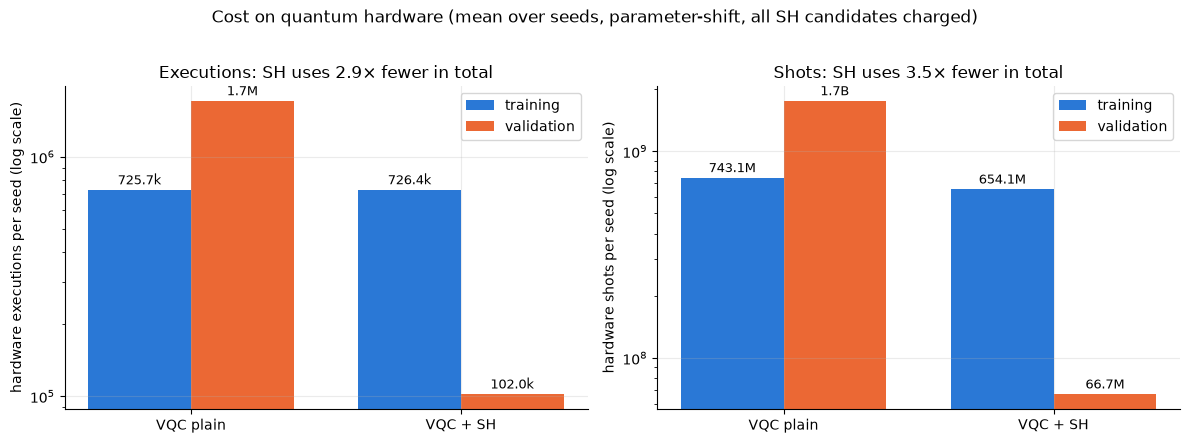

          executions               shots           
phase       training validation training validation
method                                             
VQC + SH      726.4k     102.0k   654.1M      66.7M
VQC plain     725.7k       1.7M   743.1M       1.7B


In [80]:
E = globals().get("E_TRACKED", 41)     # executions per training-example gradient (tracked in Section 15)

ledger = pd.DataFrame(LEDGER_ROWS)
ledger["executions"] = np.where(ledger["phase"] == "training",
                                ledger["example_gradients"].fillna(0) * E,
                                ledger["scored_examples"].fillna(0))
ledger["shots"] = ledger["executions"] * ledger["shots_per_execution"]

# total per seed, then mean over seeds
per_seed = ledger.groupby(["method", "seed", "phase"])[["executions", "shots"]].sum()
cost = per_seed.groupby(["method", "phase"]).mean().unstack("phase")
totals = per_seed.groupby(["method", "seed"]).sum().groupby("method").mean()

methods = ["VQC plain", "VQC + SH"]
phases = ["training", "validation"]
colors = {"training": LEGIT_COLOR, "validation": FRAUD_COLOR}


def human(v):
    for unit, div in [("B", 1e9), ("M", 1e6), ("k", 1e3)]:
        if v >= div:
            return f"{v / div:.1f}{unit}"
    return f"{v:.0f}"


fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
x = np.arange(len(methods))
for ax, metric in zip(axes, ["executions", "shots"]):
    for k, phase in enumerate(phases):
        vals = [cost.loc[m, (metric, phase)] for m in methods]
        bars = ax.bar(x + (k - 0.5) * 0.38, vals, 0.38, color=colors[phase], label=phase)
        ax.bar_label(bars, labels=[human(v) for v in vals], fontsize=9, padding=2)
    ratio = totals.loc["VQC plain", metric] / totals.loc["VQC + SH", metric]
    ax.set_xticks(x, methods)
    ax.set_yscale("log")
    ax.set_ylabel(f"hardware {metric} per seed (log scale)")
    ax.set_title(f"{metric.capitalize()}: SH uses {ratio:.1f}× fewer in total")
    ax.legend()

fig.suptitle("Cost on quantum hardware (mean over seeds, parameter-shift, all SH candidates charged)", y=1.02)
plt.tight_layout()
fig.savefig("cost_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

print(cost.map(human).to_string())


## 19 · Testing loop 1: the official protocol (judged)

`evaluate_under_noise` (Task 1, Part 11, verbatim): depolarizing channel of probability $p$ after every native gate,
exact density-matrix simulation, threshold chosen on validation **under the same noise**, metrics on the full test
set, Spearman ρ against the noiseless test scores. Three circuits per seed:

| Model | Weights | Circuit | Question it answers |
|---|---|---|---|
| VQC plain | Phase 1a | ideal | the required baseline |
| VQC + SH | Phase 1b | ideal | does SH keep (or improve) quality at lower cost? |
| VQC + SH + DD | Phase 1b | with echoes | what do 132 extra pulses cost under **gate** noise? |

Expected for the DD row: worse, since 126 → 258 noise locations and no idle noise to refocus in this model. That
is a deliberate, documented negative control; the case where DD *should* help is Section 20.

Runtime: ~3–4 min per model and seed for the ideal circuit, roughly twice that for the DD circuit.

In [78]:
OFFICIAL_FILE = Path("vqc_results_official.csv")
official_rows = []
for seed in QUANTUM_SEEDS:
    d = SEED_DATA[seed]
    runs = [("VQC plain", ideal_circuit, WEIGHTS[seed]["plain"]), ("VQC + SH", ideal_circuit, WEIGHTS[seed]["sh"])]
    if RUN_OFFICIAL_DD:
        runs.append(("VQC + SH + DD", dd_circuit, WEIGHTS[seed]["sh"]))
    for name, circuit_fn, w in runs:
        start = time.time()
        table = evaluate_under_noise(circuit_fn, w, d["Z_val"], d["Z_test"])
        official_rows.append(table.reset_index().assign(model=name, seed=seed))
        pd.concat(official_rows, ignore_index=True).to_csv(OFFICIAL_FILE, index=False)   # save as we go
        print(f"seed {seed} · {name:14s} {time.time() - start:5.0f} s   AUPRC at p = 0 / 0.01 / 0.05: "
              f"{table.loc[0.0, 'AUPRC']:.3f} / {table.loc[0.01, 'AUPRC']:.3f} / {table.loc[0.05, 'AUPRC']:.3f}")
OFFICIAL = pd.concat(official_rows, ignore_index=True)

seed 0 · VQC plain        620 s   AUPRC at p = 0 / 0.01 / 0.05: 0.503 / 0.497 / 0.421


KeyboardInterrupt: 

## 20 · Testing loop 2: superconducting T₁/T₂ noise and dynamical decoupling (Phases 2–3)

The **final SH model** is run through the superconducting model of Section 13 at stress 1, 3, 10, with and without
DD, plus an ablation without detuning (Markovian T₁/T₂ only), which isolates *what* the echo fixes. For each
configuration: threshold chosen on a stratified 20 % validation subset scored **under the same noise**, then the full
test set. Reported: AUPRC, ROC-AUC, Spearman ρ vs the noiseless scores, precision/recall/F1/MCC, test BCE (loss),
and accuracy (shown because it was requested; it is uninformative at a 0.17 % fraud rate: "always legitimate"
scores 99.83 %).

This study is **not** part of the judged protocol; it runs on `SC_SEEDS` (2 seeds by default) to keep the
runtime reasonable (~2–3 min per configuration and seed).

In [ ]:
SC_FILE = Path("vqc_results_superconducting.csv")
sc_configs = [(stress, True) for stress in SC_STRESS] + [(SC_ABLATION_STRESS, False)]
sc_rows = []
for seed in SC_SEEDS:
    d = SEED_DATA[seed]
    w = WEIGHTS[seed]["sh"]
    clean_test = predict(d["Z_test"], w)
    val_idx = nested_subset(stratified_orders(y_val, np.random.default_rng(seed + 20_000)), SC_VAL_FRACTION)
    Z_vs, y_vs = d["Z_val"][val_idx], y_val[val_idx]
    for stress, detuning in sc_configs:
        for dd_flag in (False, True):
            start = time.time()
            noise = SuperconductingNoise(stress=stress, detuning=detuning)
            s_val = sc_predict(Z_vs, w, noise, dd_flag)
            s_test = sc_predict(d["Z_test"], w, noise, dd_flag)
            threshold = choose_threshold(y_vs, s_val)
            metrics = evaluate(y_test, s_test, threshold)
            sc_rows.append({
                "seed": seed, "stress": stress, "detuning": detuning, "DD": dd_flag, **metrics,
                "accuracy": (metrics["TP"] + metrics["TN"]) / len(y_test),
                "Spearman rho": spearmanr(clean_test, s_test).statistic, "threshold": threshold,
            })
            pd.DataFrame(sc_rows).to_csv(SC_FILE, index=False)
            print(f"seed {seed} · stress {stress:>2} · detuning {'on ' if detuning else 'off'} · DD {'on ' if dd_flag else 'off'}"
                  f" · {time.time() - start:4.0f} s   AUPRC {metrics['AUPRC']:.3f}   "
                  f"ρ {sc_rows[-1]['Spearman rho']:.3f}   test BCE {metrics['log_loss']:.3f}")
SUPERCONDUCTING = pd.DataFrame(sc_rows)

## 21 · Final tables (mean ± std over seeds)

In [ ]:
def mean_std(frame, by, columns):
    grouped = frame.groupby(by)[columns]
    mean, std = grouped.mean(), grouped.std().fillna(0.0)
    out = pd.DataFrame(index=mean.index)
    for c in columns:
        out[c] = [f"{a:.3f} ± {b:.3f}" for a, b in zip(mean[c], std[c])]
    return out


metric_cols = ["AUPRC", "AUROC", "Spearman rho", "precision", "recall", "F1", "MCC"]
lr = seed_results[seed_results["seed"].isin(QUANTUM_SEEDS)]
lr_row = {c: f"{lr[c].mean():.3f} ± {lr[c].std():.3f}" for c in metric_cols if c in lr}

print("Official protocol (depolarizing per gate), test set, mean ± std over", len(QUANTUM_SEEDS), "seeds")
official_table = mean_std(OFFICIAL, ["model", "p"], metric_cols)
print(official_table.to_string())
print(f"\nlogistic regression on the same 4 inputs (noise-free): AUPRC {lr_row['AUPRC']}, AUROC {lr_row['AUROC']}")

headline = OFFICIAL[OFFICIAL["p"].isin([0.01, 0.05])].pivot_table(index="model", columns="p", values="AUPRC",
                                                                   aggfunc=["mean", "std"])
print("\nHEADLINE · test AUPRC at p = 0.01 and p = 0.05:")
for model in headline.index:
    cells = [f"p={p}: {headline.loc[model, ('mean', p)]:.3f} ± {headline.loc[model, ('std', p)]:.3f}"
             for p in (0.01, 0.05)]
    print(f"  {model:15s} " + "   ".join(cells))

print("\nSuperconducting T1/T2 (+ detuning) study, VQC + SH, mean ± std over", len(SC_SEEDS), "seeds")
print(mean_std(SUPERCONDUCTING, ["detuning", "stress", "DD"],
               ["AUPRC", "Spearman rho", "recall", "F1", "log_loss", "accuracy"]).to_string())

circuit_table = pd.DataFrame({
    "gates": [sum(counts_ideal.values()), sum(counts_dd.values())],
    "CNOTs": [counts_ideal["CNOT"], counts_dd["CNOT"]],
    "noise locations (official)": [LOCATIONS["ideal"], LOCATIONS["DD"]],
    "trainable parameters": [w_check.numel()] * 2,
}, index=["VQC (plain / SH)", "VQC + DD"])
print("\n", circuit_table.to_string())

## 22 · Figures

In [ ]:
models = list(dict.fromkeys(OFFICIAL["model"]))
colors = {"VQC plain": "0.45", "VQC + SH": LEGIT_COLOR, "VQC + SH + DD": FRAUD_COLOR}
levels = [0.0, *NOISE_LEVELS]
xpos = np.arange(len(levels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, metric in zip(axes, ["AUPRC", "Spearman rho"]):
    for k, model in enumerate(models):
        part = OFFICIAL[OFFICIAL["model"] == model].groupby("p")[metric]
        ax.errorbar(xpos + 0.06 * (k - 1), part.mean().reindex(levels), yerr=part.std().reindex(levels), marker="o",
                    capsize=3, linewidth=2, color=colors.get(model), label=model)
    if metric == "AUPRC":
        m, s = lr["AUPRC"].mean(), lr["AUPRC"].std()
        ax.axhspan(m - s, m + s, color="0.8", alpha=0.6, label=f"logistic regression ({m:.3f} ± {s:.3f})")
        ax.axhline(y_test.mean(), color="0.5", linestyle=":", linewidth=1, label="no skill")
    ax.set_xticks(xpos, [str(p) for p in levels])
    ax.set_xlabel("depolarizing probability p per gate")
    ax.set_title(f"Official protocol · test {metric} (mean ± std, {len(QUANTUM_SEEDS)} seeds)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
with_detuning = SUPERCONDUCTING[SUPERCONDUCTING["detuning"]]
markov = SUPERCONDUCTING[~SUPERCONDUCTING["detuning"]]
for ax, metric in zip(axes, ["AUPRC", "Spearman rho"]):
    for dd_flag, color in ((False, "0.45"), (True, FRAUD_COLOR)):
        part = with_detuning[with_detuning["DD"] == dd_flag].groupby("stress")[metric]
        ax.errorbar(part.mean().index, part.mean(), yerr=part.std().fillna(0), marker="o", capsize=3, linewidth=2,
                    color=color, label=f"T1/T2 + detuning, DD {'on' if dd_flag else 'off'}")
        mpart = markov[markov["DD"] == dd_flag].groupby("stress")[metric]
        ax.scatter(mpart.mean().index, mpart.mean(), marker="s", s=60, facecolors="none", edgecolors=color,
                   label=f"T1/T2 only (no detuning), DD {'on' if dd_flag else 'off'}")
    ax.set_xscale("log")
    ax.set_xticks(SC_STRESS, [str(s) for s in SC_STRESS])
    ax.set_xlabel("noise stress factor (1 = transmon profile of Section 12)")
    ax.set_title(f"Superconducting model · test {metric}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
tracked = COST[COST["E"] == "tracked"].groupby("method")
for ax, (column, title) in zip(axes, [("total executions", "Circuit executions"), ("total shots", "Shots")]):
    train_col = "train executions" if column == "total executions" else "train shots"
    val_col = "validation executions" if column == "total executions" else "validation shots"
    means = tracked[[train_col, val_col]].mean()
    ax.bar(means.index, means[train_col], color=LEGIT_COLOR, label="training")
    ax.bar(means.index, means[val_col], bottom=means[train_col], color=FRAUD_COLOR, label="validation")
    ax.set_yscale("log")
    ax.set_title(f"{title} on hardware (E tracked = {E_TRACKED:.0f})")
    ax.legend()
plt.tight_layout()
plt.show()

## 23 · How to read the results (and what goes on the slides)

- **Deliverable 1 (baseline)**: "VQC plain" rows of Section 21, official protocol, 5 seeds.
- **Deliverable 2 (improvement)**: successive halving (cost, and possibly stability across seeds); DD is evaluated
  honestly under both noise models. Under the **official** gate-only model DD can only add noise (126 → 258
  locations): report it as a negative control. Under the **superconducting** model with quasi-static detuning, the
  echo refocuses the coherent idle phase; compare DD on/off at each stress and with the detuning-free ablation to
  show *which* noise it fixes (coherent detuning: yes; Markovian phase damping: no).
- **Deliverable 3 (classical reference)**: logistic regression on the same 4 inputs (Section 10), shown as the grey
  band in the first figure.
- **Deliverable 4 (cost ledger)**: Section 18; both E conventions; every SH candidate is charged.
- **Robustness**: read AUPRC **with** Spearman ρ: an AUPRC that rises under noise while ρ falls is a reshuffle,
  not an improvement (the trap described in the brief).
- **What did not work / next steps**: whatever the tables show; candidates are shallower circuits (fewer noise
  locations), DD only in idle windows that exceed a threshold, and noise-aware training.

**Reproducibility**: fixed seeds everywhere; the split is checked against `split_indices.npz`; every result table
is written to CSV as it is produced (`classical_baseline_results.csv`, `vqc_results_official.csv`,
`vqc_results_superconducting.csv`, `vqc_cost_ledger.csv`, `vqc_successive_halving_log.csv`).